# 01 · UTKFace: data exploration

**Goal:** understand the data before designing anything. This notebook covers:
1. How many images there are and whether every filename parses into labels.
2. Image properties (size, colour mode, duplicates).
3. The **target** (age): its distribution, skew, and "age heaping".
4. The **group labels** (gender, race) and how they interact with age. This is the starting point for the bias analysis the assignment asks for (Section 3.1).
5. A preview of the **mean/median predictor** (the trivial baseline), overall and per group.
6. Example images.

> **Test-set hygiene:** this notebook only looks at *labels and a few images* of the whole dataset to understand the problem. It does **not** fit or tune anything. The split, the baseline, and the normalisation statistics are computed later **on the training split only**.

No training happens here, so no CodeCarbon tracker is needed. The notebook only reads files.

In [1]:
import hashlib
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

SEED = 655
rng = np.random.default_rng(SEED)

# find the repo root whether the notebook runs from src/ or from the repo root
REPO = Path.cwd()
while not (REPO / "requirements.txt").exists():
    REPO = REPO.parent
IMG_DIR = REPO / "data" / "raw" / "UTKFace"
FIG_DIR = REPO / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

GENDER = {0: "male", 1: "female"}
RACE = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("images dir:", IMG_DIR, "| exists:", IMG_DIR.exists())

images dir: C:\Users\fouad.aladhami\coding\project\CSE655_Deep_Learning_Project\data\raw\UTKFace | exists: True


## 1. Parse labels from the filenames

The labels are encoded in each filename: `[age]_[gender]_[race]_[date&time].jpg.chip.jpg`
- **age**: integer 0–116
- **gender**: 0 = male, 1 = female
- **race**: 0 = White, 1 = Black, 2 = Asian, 3 = Indian, 4 = Others

We parse with a strict regular expression, so a malformed filename is *reported* instead of silently mislabelled.

In [2]:
PATTERN = re.compile(r"^(\d+)_(\d)_(\d)_(\d+)\.jpg\.chip\.jpg$")

rows, bad = [], []
for p in sorted(IMG_DIR.iterdir()):
    m = PATTERN.match(p.name)
    if m is None:
        bad.append(p.name)
        continue
    age, g, r, ts = m.groups()
    rows.append({"file": p.name, "age": int(age), "gender": int(g), "race": int(r), "timestamp": ts})

df = pd.DataFrame(rows)
print(f"files in folder      : {len(rows) + len(bad)}")
print(f"parsed OK            : {len(df)}")
print(f"malformed filenames  : {len(bad)} -> {bad}")
print(f"gender values        : {sorted(df.gender.unique())}")
print(f"race values          : {sorted(df.race.unique())}")
df.head()

files in folder      : 23708
parsed OK            : 23703
malformed filenames  : 5 -> ['24_0_1_20170116220224657 .jpg.chip.jpg', '39_1_20170116174525125.jpg.chip.jpg', '55_0_0_20170116232725357jpg.chip.jpg', '61_1_20170109142408075.jpg.chip.jpg', '61_1_20170109150557335.jpg.chip.jpg']
gender values        : [np.int64(0), np.int64(1)]
race values          : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,file,age,gender,race,timestamp
0,100_0_0_20170112213500903.jpg.chip.jpg,100,0,0,20170112213500903
1,100_0_0_20170112215240346.jpg.chip.jpg,100,0,0,20170112215240346
2,100_1_0_20170110183726390.jpg.chip.jpg,100,1,0,20170110183726390
3,100_1_0_20170112213001988.jpg.chip.jpg,100,1,0,20170112213001988
4,100_1_0_20170112213303693.jpg.chip.jpg,100,1,0,20170112213303693


## 2. Image properties

We check sizes and colour modes, because they decide the input pipeline. We also hash every file to find **exact duplicates**: the same image in train *and* test would leak information and make the test error look better than it is.

In [3]:
sizes, modes, hashes = Counter(), Counter(), {}
for f in df.file:
    path = IMG_DIR / f
    with Image.open(path) as im:          # opening only reads the header -> fast
        sizes[im.size] += 1
        modes[im.mode] += 1
    hashes[f] = hashlib.md5(path.read_bytes()).hexdigest()

df["md5"] = df.file.map(hashes)
print("image sizes :", dict(sizes))
print("colour modes:", dict(modes))
dup_groups = df[df.duplicated("md5", keep=False)].groupby("md5")
print(f"exact-duplicate groups: {dup_groups.ngroups}  (images involved: {sum(len(g) for _, g in dup_groups)})")
conflicting = [g for _, g in dup_groups if g[["age", "gender", "race"]].nunique().max() > 1]
print(f"duplicate groups whose labels DISAGREE: {len(conflicting)}")
for g in conflicting[:5]:
    print(g[["file", "age", "gender", "race"]].to_string(index=False), "\n")

image sizes : {(200, 200): 23703}
colour modes: {'RGB': 23703}
exact-duplicate groups: 375  (images involved: 765)


duplicate groups whose labels DISAGREE: 259
                                 file  age  gender  race
24_1_0_20170105162704533.jpg.chip.jpg   24       1     0
31_1_0_20170105162708403.jpg.chip.jpg   31       1     0 

                                 file  age  gender  race
33_0_1_20170117173931669.jpg.chip.jpg   33       0     1
33_1_1_20170117173927950.jpg.chip.jpg   33       1     1 

                                 file  age  gender  race
28_1_2_20170109141410232.jpg.chip.jpg   28       1     2
32_1_2_20170109141403511.jpg.chip.jpg   32       1     2 

                                 file  age  gender  race
52_1_0_20170104002309261.jpg.chip.jpg   52       1     0
61_1_0_20170117204812272.jpg.chip.jpg   61       1     0 

                                 file  age  gender  race
26_1_1_20170116174149455.jpg.chip.jpg   26       1     1
28_1_1_20170116164832811.jpg.chip.jpg   28       1     1 




### 2.1 How the duplicate check works (hashing)

A **hash function** turns any sequence of bytes into a short fixed-length "fingerprint". We use **MD5**, which gives 128 bits, written as 32 hexadecimal characters.

Three properties make it useful here:
1. **Deterministic:** the same bytes always give the same hash. Two files with the same hash are, for practical purposes, the same file.
2. **Avalanche effect:** changing even **one bit** of the input gives a completely different hash. Similar-looking files therefore do *not* get similar hashes.
3. **Collisions are negligible:** two *different* files sharing a hash has a probability of about $n^2 / 2^{129}$. For $n = 23{,}703$ files that is ~$10^{-30}$. (MD5 is broken for *security*, where an attacker crafts collisions on purpose, but that doesn't matter for finding accidental copies.)

The procedure in the cell above:
1. Read every file's **raw bytes**, i.e. the JPEG file as stored, not the decoded pixels.
2. Compute `md5(bytes)` → one 32-character string per file.
3. `groupby(md5)`: every group with more than one file is a set of **exact copies**.
4. Within each group, compare the labels (age, gender, race). If they differ, the *same photo* was labelled twice differently.

**Limitation:** this only finds *byte-identical* copies. If a photo was re-saved, resized or re-compressed, its bytes change and the hash is completely different, even though it looks identical. Finding those would need a *perceptual* hash (e.g. aHash/dHash, which hash a tiny blurred greyscale version) or embedding similarity. We don't do that here and mention it as a limitation.


In [4]:

# Demo on one real duplicate pair
pair = dup_groups.get_group(next(iter(dup_groups.groups))).file.tolist()[:2]
b0, b1 = (IMG_DIR / pair[0]).read_bytes(), (IMG_DIR / pair[1]).read_bytes()
print("file A :", pair[0], "|", len(b0), "bytes | md5", hashlib.md5(b0).hexdigest())
print("file B :", pair[1], "|", len(b1), "bytes | md5", hashlib.md5(b1).hexdigest())
print("bytes identical :", b0 == b1)
print("pixels identical:", np.array_equal(np.asarray(Image.open(IMG_DIR / pair[0])), np.asarray(Image.open(IMG_DIR / pair[1]))))

# Avalanche effect: flip ONE bit in the last byte of file A
flipped = b0[:-1] + bytes([b0[-1] ^ 0b00000001])
print("\nA with 1 bit flipped -> md5", hashlib.md5(flipped).hexdigest(), "(completely different)")


file A : 21_0_2_20170103234754659.jpg.chip.jpg | 5881 bytes | md5 009fa4c83098f3da81209b5d964947e6
file B : 21_0_2_20170117193634310.jpg.chip.jpg | 5881 bytes | md5 009fa4c83098f3da81209b5d964947e6
bytes identical : True
pixels identical: True

A with 1 bit flipped -> md5 dfe512eae3e9f06c9b62e8fc220e2650 (completely different)



### 2.2 How many images are duplicated, and why do the labels conflict?

Left: every image falls in exactly one category. It is either **unique**, or a member of a duplicate group whose labels **agree** or **conflict**. Right: the same view counted in *groups* instead of images.

The second chart breaks the conflicting groups down by **which label disagrees**. The categories are exclusive (e.g. "age + race" means both differ but gender agrees), so the bars add up to the number of conflicting groups.


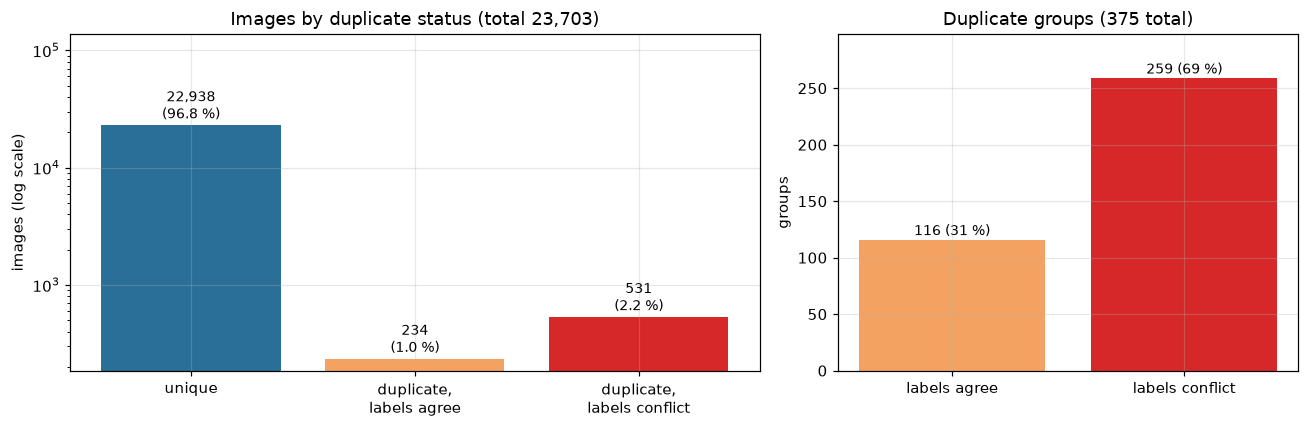

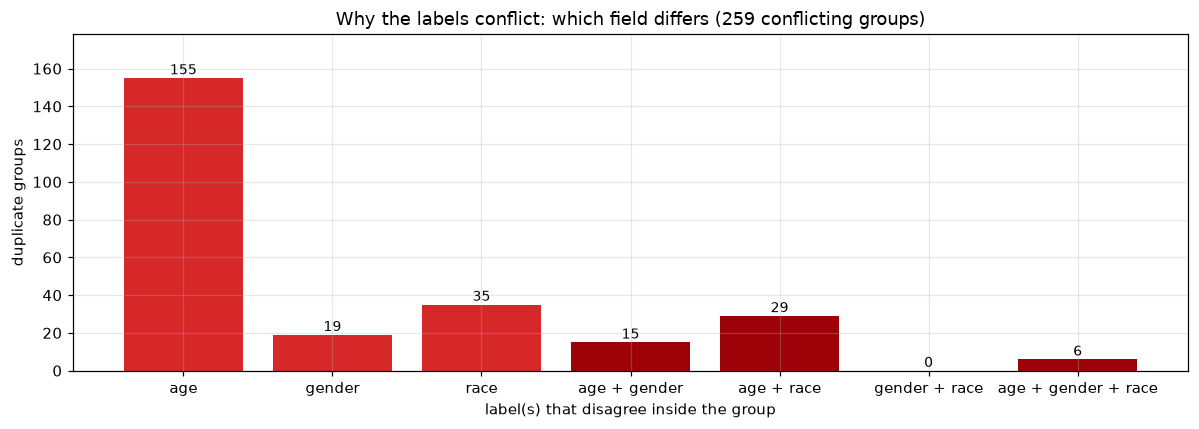

age gap inside the 205 age-conflicting groups:
count    205.0
mean       7.9
std        8.3
min        1.0
25%        2.0
50%        5.0
75%       10.0
max       48.0


In [5]:

def group_info(g):
    return pd.Series({"n": len(g), "age_gap": g.age.max() - g.age.min(),
                      "age_conflict": g.age.nunique() > 1,
                      "gender_conflict": g.gender.nunique() > 1,
                      "race_conflict": g.race.nunique() > 1})

info = dup_groups.apply(group_info)
info["any_conflict"] = info[["age_conflict", "gender_conflict", "race_conflict"]].any(axis=1)

# ---- chart 1: images / groups by duplicate status --------------------------------------
n_conf_img = int(info.loc[info.any_conflict, "n"].sum())
n_cons_img = int(info.loc[~info.any_conflict, "n"].sum())
n_unique = len(df) - n_conf_img - n_cons_img
img_counts = pd.Series({"unique": n_unique, "duplicate,\nlabels agree": n_cons_img,
                        "duplicate,\nlabels conflict": n_conf_img})
grp_counts = pd.Series({"labels agree": int((~info.any_conflict).sum()),
                        "labels conflict": int(info.any_conflict.sum())})
COLORS = ["#2a6f97", "#f4a261", "#d62828"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 2]})
bars = a1.bar(img_counts.index, img_counts.values, color=COLORS)
a1.set_yscale("log")   # log scale: otherwise the small bars are invisible next to 22,938
a1.set(title=f"Images by duplicate status (total {len(df):,})", ylabel="images (log scale)")
for b, v in zip(bars, img_counts.values):
    a1.text(b.get_x() + b.get_width() / 2, v * 1.15, f"{v:,}\n({100 * v / len(df):.1f} %)", ha="center", fontsize=9)
a1.set_ylim(top=img_counts.max() * 6)

bars = a2.bar(grp_counts.index, grp_counts.values, color=COLORS[1:])
a2.set(title=f"Duplicate groups ({len(info)} total)", ylabel="groups")
for b, v in zip(bars, grp_counts.values):
    a2.text(b.get_x() + b.get_width() / 2, v + 4, f"{v} ({100 * v / len(info):.0f} %)", ha="center", fontsize=9)
a2.set_ylim(top=grp_counts.max() * 1.15)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_duplicate_counts.png"); plt.show()

# ---- chart 2: which label disagrees (exclusive combinations) ---------------------------
conf = info[info.any_conflict]
def reason(r):
    parts = [n for n, flag in [("age", r.age_conflict), ("gender", r.gender_conflict), ("race", r.race_conflict)] if flag]
    return " + ".join(parts)
reasons = conf.apply(reason, axis=1).value_counts()
order_r = ["age", "gender", "race", "age + gender", "age + race", "gender + race", "age + gender + race"]
reasons = reasons.reindex(order_r, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(reasons.index, reasons.values, color=["#d62828"] * 3 + ["#9d0208"] * 4)
for b, v in zip(bars, reasons.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, str(v), ha="center", fontsize=9)
ax.set(title=f"Why the labels conflict: which field differs ({len(conf)} conflicting groups)",
       ylabel="duplicate groups", xlabel="label(s) that disagree inside the group")
ax.set_ylim(top=reasons.max() * 1.15)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_conflict_reasons.png"); plt.show()

print(f"age gap inside the {int(info.age_conflict.sum())} age-conflicting groups:")
print(info.loc[info.age_conflict, "age_gap"].describe().round(1).to_string())



### 2.3 Gallery of duplicate groups

The images are laid out in a grid of 8 columns. Each **group of identical images sits next to each other and shares a frame colour**, and the tag above it (`#1`, `#2`, …) gives the group and the type of conflict. Under the tag, the labels from the filename are shown with the **disagreeing field in red**.
Groups shown, in order: the 8 largest age gaps, then 4 gender conflicts, 4 race conflicts, and 4 groups whose labels agree.


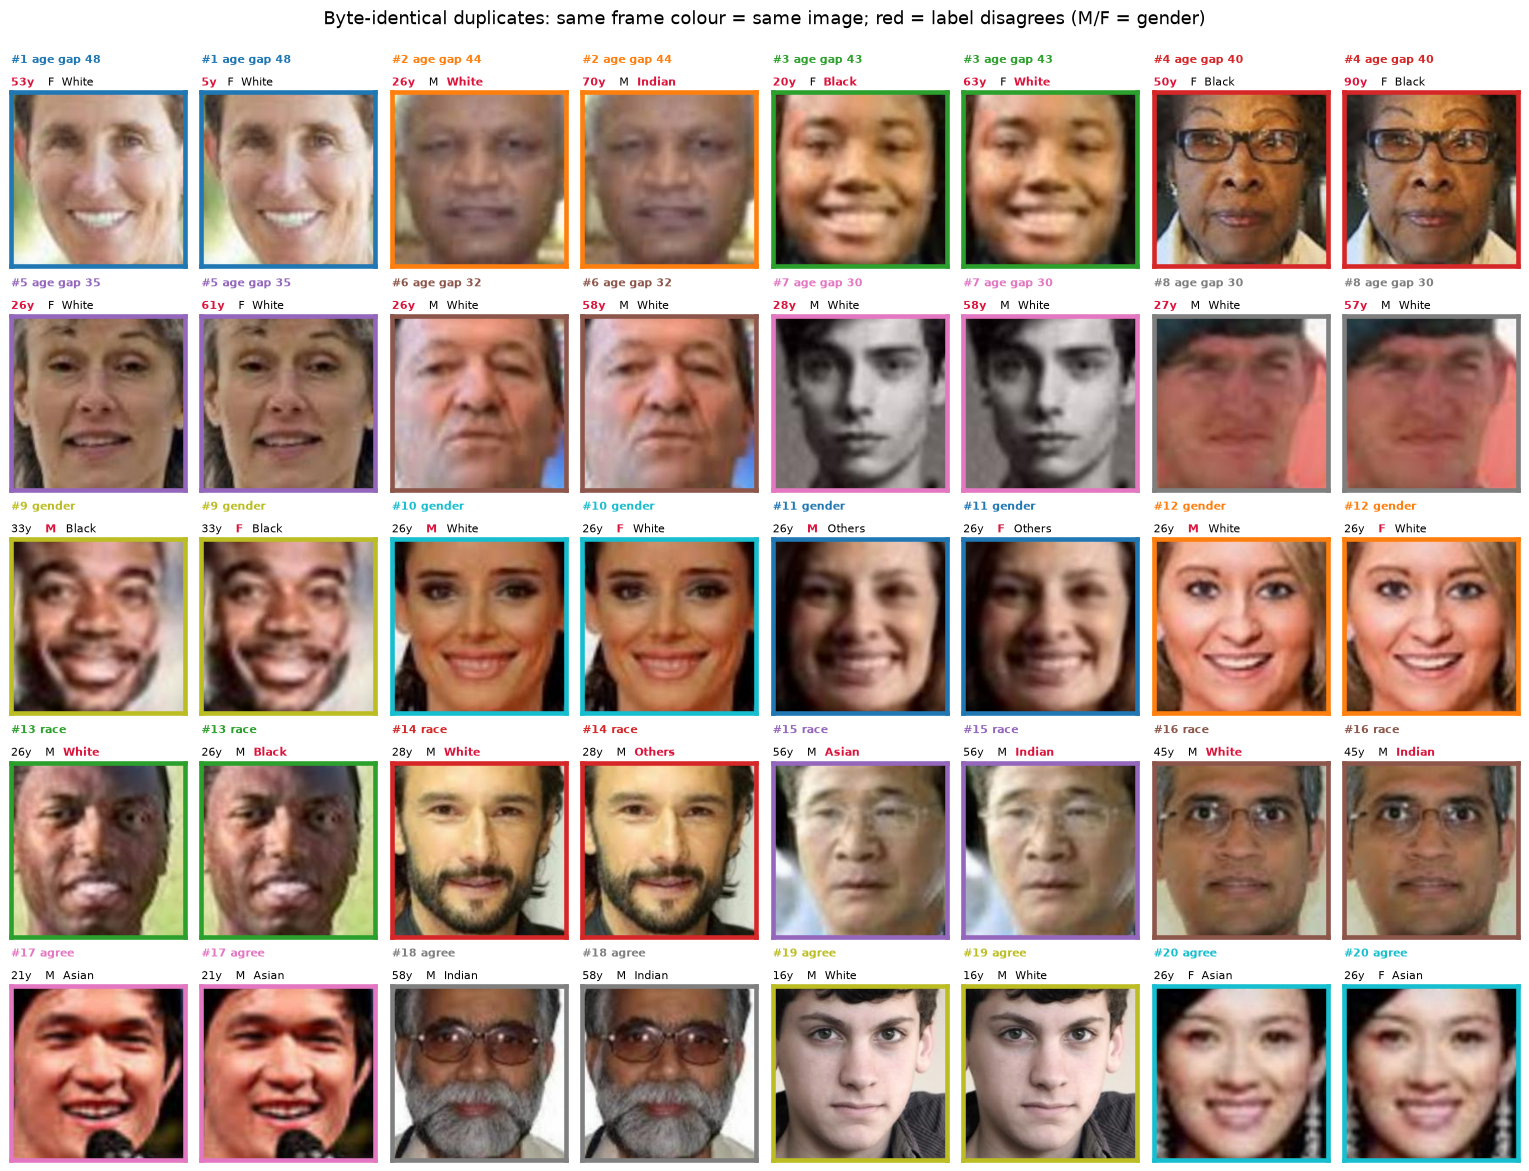

In [6]:

NCOLS = 8
groups_to_show = (
    [("age gap", h) for h in info.sort_values("age_gap", ascending=False).index[:8]]
    + [("gender", h) for h in info[info.gender_conflict & ~info.age_conflict].index[:4]]
    + [("race", h) for h in info[info.race_conflict & ~info.age_conflict & ~info.gender_conflict].index[:4]]
    + [("agree", h) for h in info[~info.any_conflict].index[:4]]
)

# pack groups into rows of NCOLS cells without splitting a group across two rows
slots, row, col = [], 0, 0
for gi, (kind, h) in enumerate(groups_to_show):
    g = df[df.md5 == h]
    if col + len(g) > NCOLS:
        row, col = row + 1, 0
    for j in range(len(g)):
        slots.append((row, col, gi, kind, h, g, j))
        col += 1
nrows = row + 1

palette = plt.cm.tab10.colors
fig, axes = plt.subplots(nrows, NCOLS, figsize=(1.75 * NCOLS, 2.15 * nrows))
axes = np.atleast_2d(axes)
for ax in axes.ravel():
    ax.axis("off")

fig.canvas.draw()
for r, c, gi, kind, h, g, j in slots:
    ax = axes[r, c]
    ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor(palette[gi % 10]); s.set_linewidth(3)
    rec = g.iloc[j]
    ax.imshow(Image.open(IMG_DIR / rec.file))
    tag = f"#{gi + 1} " + (f"age gap {int(info.loc[h, 'age_gap'])}" if kind == "age gap" else kind)
    ax.text(0, 1.17, tag, transform=ax.transAxes, fontsize=7, color=palette[gi % 10], fontweight="bold")
    bad = {"age": g.age.nunique() > 1, "gender": g.gender.nunique() > 1, "race": g.race.nunique() > 1}
    x = 0.0
    for text, is_bad in [(f"{rec.age}y", bad["age"]), (GENDER[rec.gender][0].upper(), bad["gender"]), (RACE[rec.race], bad["race"])]:
        t = ax.text(x, 1.04, text + " ", transform=ax.transAxes, fontsize=7.5,
                    color="crimson" if is_bad else "black", fontweight="bold" if is_bad else "normal")
        x += t.get_window_extent(renderer=fig.canvas.get_renderer()).width / ax.get_window_extent().width

fig.suptitle("Byte-identical duplicates: same frame colour = same image; red = label disagrees (M/F = gender)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_duplicates.png", bbox_inches="tight"); plt.show()


## 3. The target: age

For regression the distribution of the target matters a lot:
- A **skewed** target makes MSE focus on the rare large errors (old people). MAE and Huber are more robust.
- The **mean predictor's MAE** is the reference for the "acceptable" rule (MAE_own ≤ 0.6 × MAE_mean).
- **Age heaping:** people often report round ages (30, 40, 50 …). If the labels pile up on multiples of 5/10, they are partly *estimated*, which puts a floor on the error any model can reach.

count    23703.00
mean        33.30
std         19.89
min          1.00
25%         23.00
50%         29.00
75%         45.00
max        116.00
skewness: 0.62


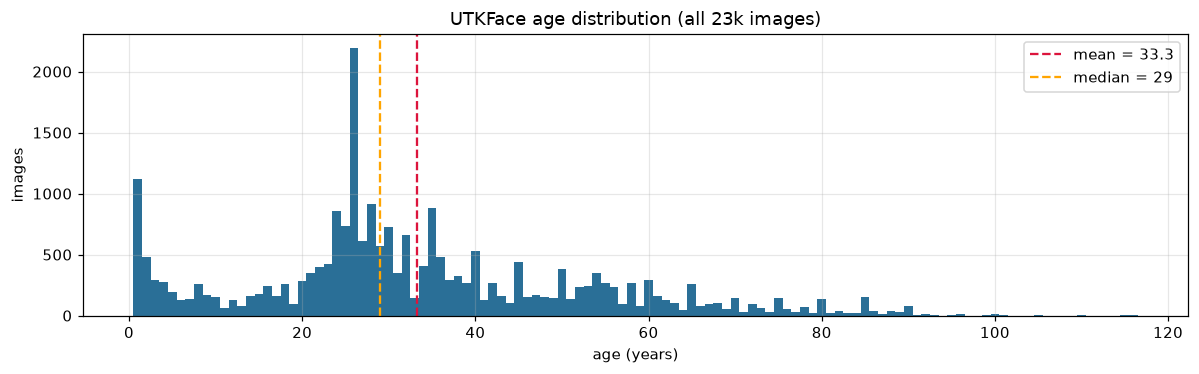

In [7]:
print(df.age.describe().round(2).to_string())
print(f"skewness: {df.age.skew():.2f}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(*np.unique(df.age, return_counts=True), width=1.0, color="#2a6f97")
ax.axvline(df.age.mean(), color="crimson", ls="--", label=f"mean = {df.age.mean():.1f}")
ax.axvline(df.age.median(), color="orange", ls="--", label=f"median = {df.age.median():.0f}")
ax.set(xlabel="age (years)", ylabel="images", title="UTKFace age distribution (all 23k images)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_age_hist.png"); plt.show()

In [8]:
# Age heaping: compare counts at multiples of 10 with the average of their two neighbours (age ±1)
counts = df.age.value_counts().reindex(range(df.age.max() + 1), fill_value=0)
heap = pd.DataFrame({
    "count": [counts[a] for a in range(20, 91, 10)],
    "neighbours_avg": [(counts[a - 1] + counts[a + 1]) / 2 for a in range(20, 91, 10)],
}, index=range(20, 91, 10))
heap["ratio"] = (heap["count"] / heap["neighbours_avg"]).round(2)
heap

,count,neighbours_avg,ratio
20,284,222.0,1.28
30,724,460.0,1.57
40,526,198.5,2.65
50,381,143.0,2.66
60,293,120.5,2.43
70,147,44.5,3.30
80,133,22.5,5.91
90,82,17.5,4.69


In [9]:
BANDS = [0, 3, 13, 20, 30, 40, 50, 60, 70, 80, 117]
LABELS = ["0-2", "3-12", "13-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
df["age_band"] = pd.cut(df.age, bins=BANDS, labels=LABELS, right=False)
band = df.age_band.value_counts().reindex(LABELS)
pd.DataFrame({"images": band, "%": (100 * band / len(df)).round(1)}).T

age_band,0-2,3-12,13-19,20-29,30-39,40-49,50-59,60-69,70-79,80+
images,1605.0,1808.0,1180.0,7343.0,4536.0,2245.0,2298.0,1316.0,699.0,673.0
%,6.8,7.6,5.0,31.0,19.1,9.5,9.7,5.6,2.9,2.8


## 4. Group labels: gender and race

The assignment asks us to report the error **per group** and comment on bias. First we need to know how large the groups are: a small group gives a noisy per-group MAE, and the model sees fewer examples of it.

In [10]:
def count_table(col, names):
    c = df[col].map(names).value_counts()
    return pd.DataFrame({"images": c, "%": (100 * c / len(df)).round(1)})

display(count_table("gender", GENDER))
display(count_table("race", RACE))
ct = pd.crosstab(df.race.map(RACE), df.gender.map(GENDER), margins=True)
ct

,images,%
gender,,
male,12389,52.3
female,11314,47.7


,images,%
race,,
White,10077,42.5
Black,4525,19.1
Indian,3975,16.8
Asian,3434,14.5
Others,1692,7.1


gender,female,male,All
race,,,
Asian,1859,1575,3434
Black,2208,2317,4525
Indian,1714,2261,3975
Others,932,760,1692
White,4601,5476,10077
All,11314,12389,23703


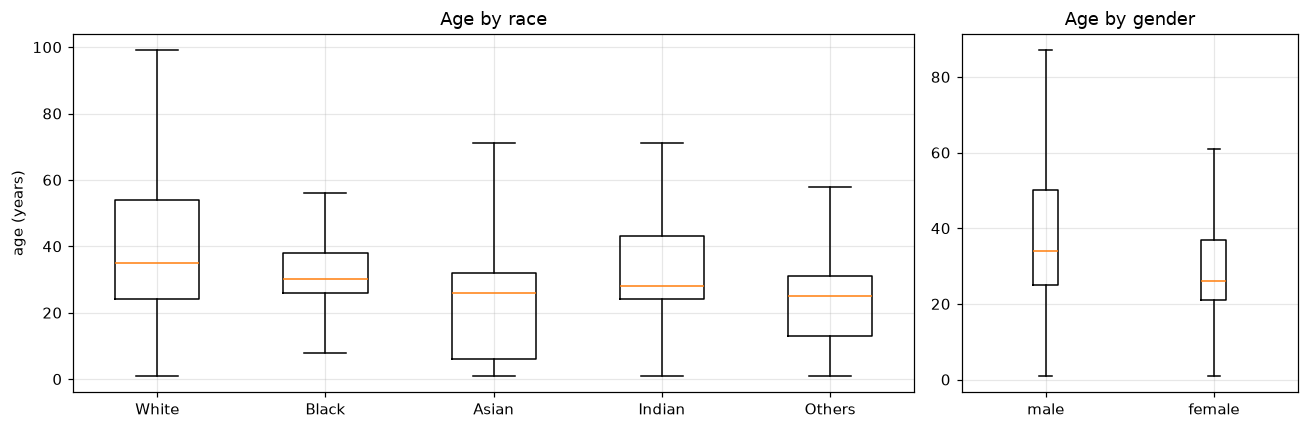

,count,mean,median,std
race,,,,
Asian,3434,25.9,26.0,20.4
Black,4525,33.9,30.0,14.8
Indian,3975,31.5,28.0,17.0
Others,1692,23.2,25.0,14.5
White,10077,38.0,35.0,21.9


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [5, 2]})
order = list(RACE.values())
axes[0].boxplot([df.loc[df.race.map(RACE) == r, "age"] for r in order], tick_labels=order, showfliers=False)
axes[0].set(title="Age by race", ylabel="age (years)")
axes[1].boxplot([df.loc[df.gender == g, "age"] for g in GENDER], tick_labels=list(GENDER.values()), showfliers=False)
axes[1].set(title="Age by gender")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_age_by_group.png"); plt.show()

df.groupby(df.race.map(RACE))["age"].agg(["count", "mean", "median", "std"]).round(1)

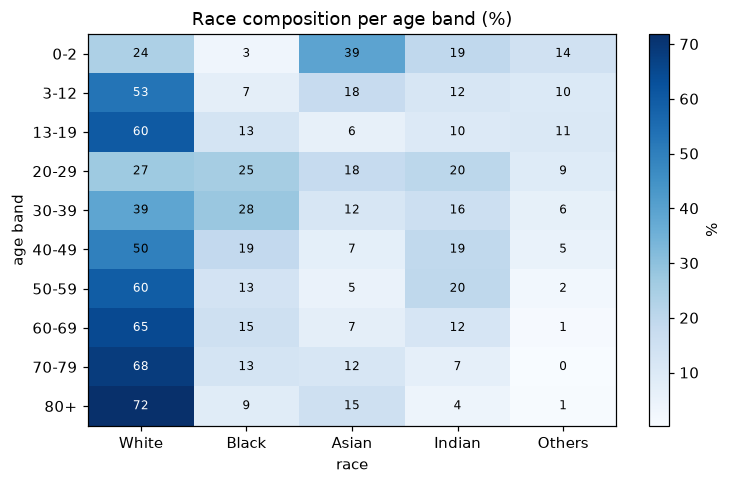

age_band,0-2,3-12,13-19,20-29,30-39,40-49,50-59,60-69,70-79,80+
gender,,,,,,,,,,
female,45.6,59.4,55.8,58.3,45.4,32.3,27.9,35.9,37.1,61.1
male,54.4,40.6,44.2,41.7,54.6,67.7,72.1,64.1,62.9,38.9


In [12]:
# Share of each race inside each age band (rows sum to 100 %)
tab = pd.crosstab(df.age_band, df.race.map(RACE), normalize="index").mul(100).round(1)[order]
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(tab.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(order)), order); ax.set_yticks(range(len(LABELS)), LABELS)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        ax.text(j, i, f"{tab.values[i, j]:.0f}", ha="center", va="center",
                color="white" if tab.values[i, j] > 50 else "black", fontsize=8)
ax.set(title="Race composition per age band (%)", xlabel="race", ylabel="age band")
ax.grid(False); fig.colorbar(im, ax=ax, label="%")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_race_by_ageband.png"); plt.show()

# Gender share per age band
pd.crosstab(df.age_band, df.gender.map(GENDER), normalize="index").mul(100).round(1).T

## 5. Preview: the trivial baseline

A model that always predicts one number $c$:
- Predicting the **mean** minimises MSE. Predicting the **median** minimises MAE. So the median predictor has a lower MAE.
- Here they are computed on *all* labels, for intuition only. The official baseline uses the **training split** and is evaluated on the test split.

The per-group error of this constant predictor already shows a "bias": groups whose ages are far from the global mean (children, the elderly) get large errors **even though the model looks at nothing**. A trained model's per-group errors should be read against this reference.

In [13]:
y = df.age.to_numpy(dtype=float)
for name, c in [("mean", y.mean()), ("median", np.median(y))]:
    err = y - c
    print(f"{name:>6} predictor (c = {c:5.1f}):  MAE = {np.abs(err).mean():5.2f}   RMSE = {np.sqrt((err**2).mean()):5.2f}")

mae_mean = np.abs(y - y.mean()).mean()
print(f"\n'acceptable' needs MAE_own <= 0.6 x MAE_mean ~= {0.6 * mae_mean:.1f} years (preview)")

df["abs_err_mean"] = (df.age - y.mean()).abs()
for col, names in [("gender", GENDER), ("race", RACE)]:
    print(f"\nMAE of the global-mean predictor per {col}:")
    print(df.groupby(df[col].map(names))["abs_err_mean"].mean().round(2).to_string())
print("\nper age band:")
print(df.groupby("age_band", observed=True)["abs_err_mean"].mean().round(1).to_string())

  mean predictor (c =  33.3):  MAE = 15.35   RMSE = 19.89
median predictor (c =  29.0):  MAE = 14.97   RMSE = 20.35

'acceptable' needs MAE_own <= 0.6 x MAE_mean ~= 9.2 years (preview)

MAE of the global-mean predictor per gender:
gender
female    15.14
male      15.54

MAE of the global-mean predictor per race:
race
Asian     16.92
Black     10.64
Indian    13.43
Others    14.24
White     17.87

per age band:
age_band
0-2      32.0
3-12     26.6
13-19    17.1
20-29     7.9
30-39     2.5
40-49    10.4
50-59    20.6
60-69    30.2
70-79    40.4
80+      53.2


## 6. Look at the images

Random examples with their labels, then a few per age band. Things to look for: crop/alignment quality, pose, lighting, greyscale photos, occlusion (glasses, hands), and labels that look wrong.

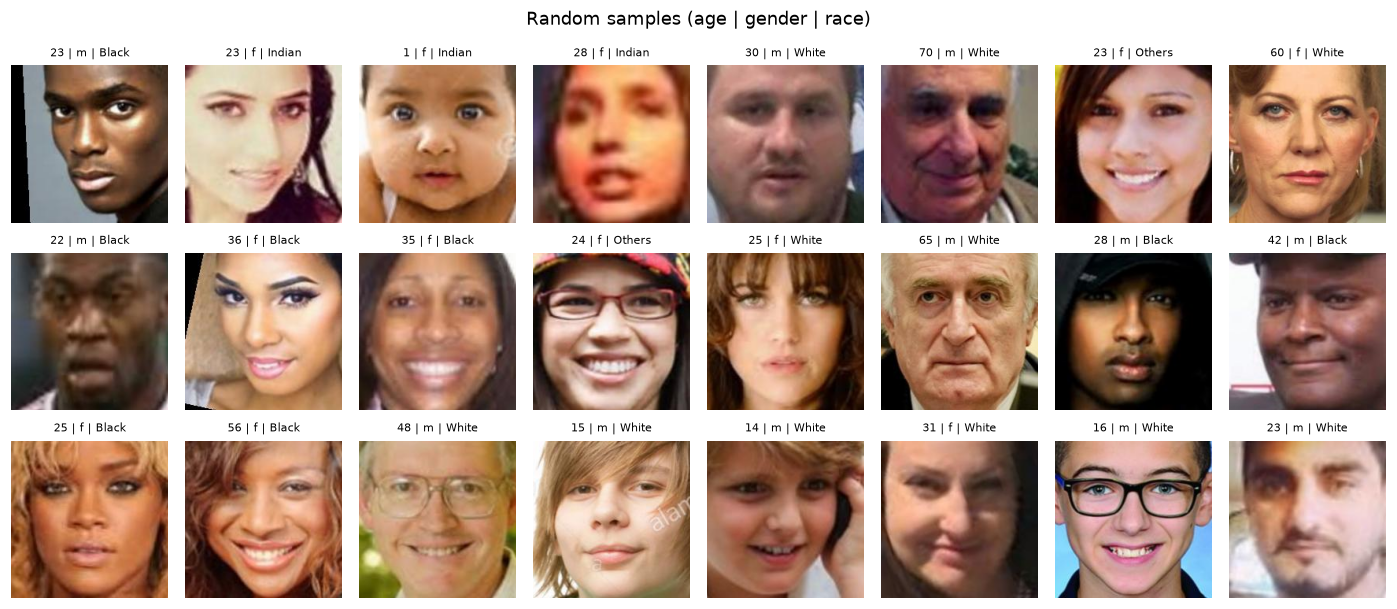

In [14]:
def show(files, ncols=8, title=None, fname=None):
    nrows = int(np.ceil(len(files) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.6 * ncols, 1.9 * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, f in zip(np.ravel(axes), files):
        r = df.loc[df.file == f].iloc[0]
        ax.imshow(Image.open(IMG_DIR / f))
        ax.set_title(f"{r.age} | {GENDER[r.gender][0]} | {RACE[r.race]}", fontsize=7)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname)
    plt.show()

show(rng.choice(df.file, 24, replace=False), title="Random samples (age | gender | race)", fname="eda_samples.png")

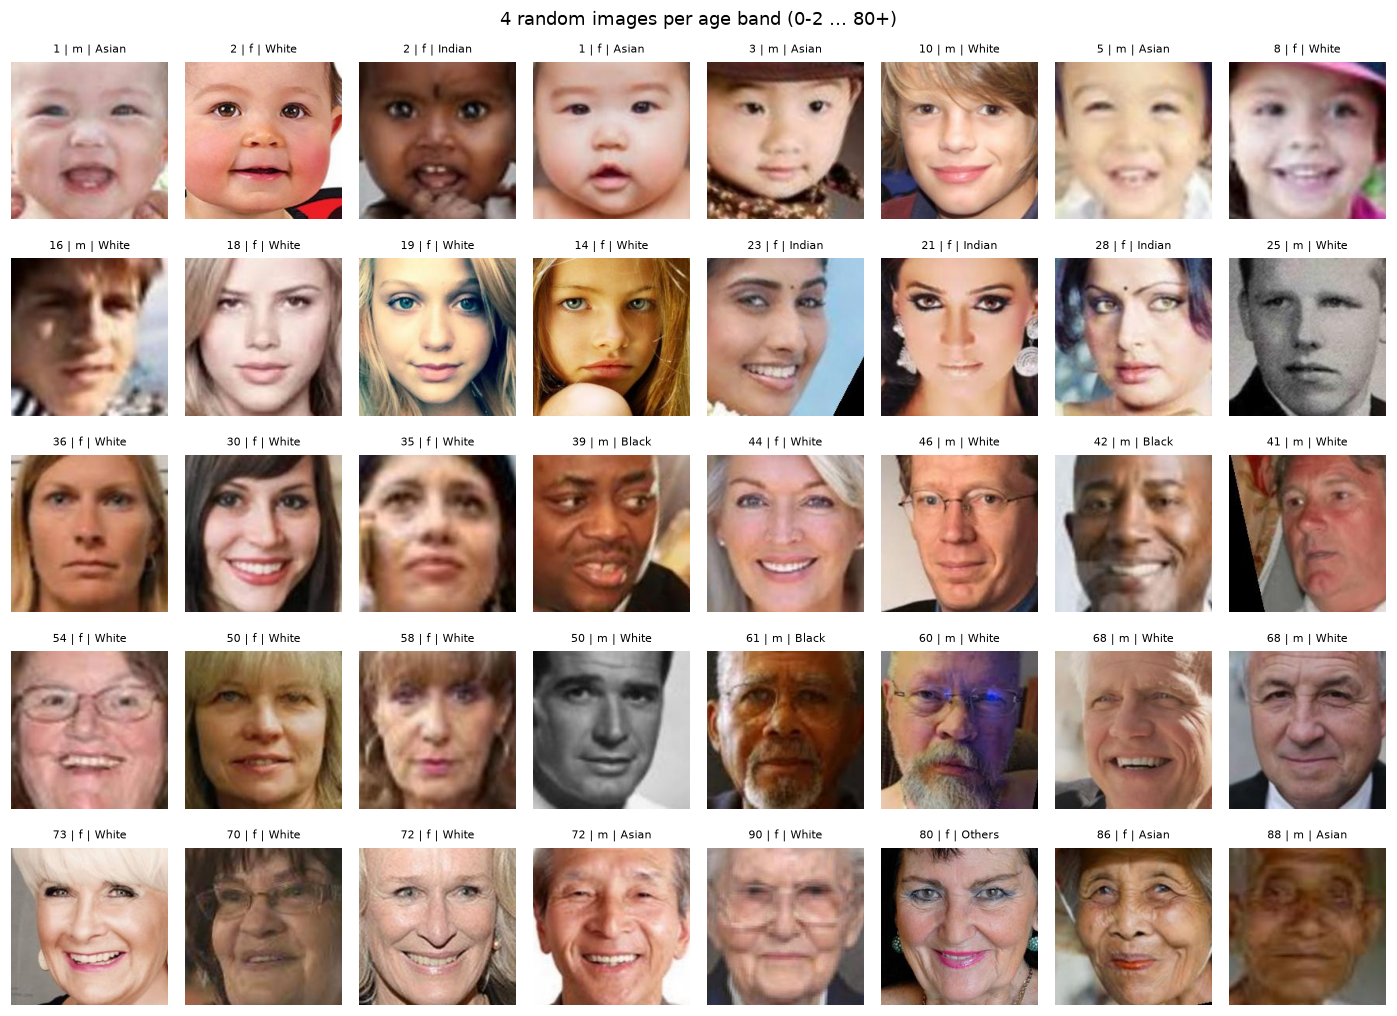

In [15]:
per_band = [f for b in LABELS for f in rng.choice(df.loc[df.age_band == b, "file"], 4, replace=False)]
show(per_band, ncols=8, title="4 random images per age band (0-2 … 80+)")

greyscale-looking images in a random sample of 2000: 56 (2.8 %)


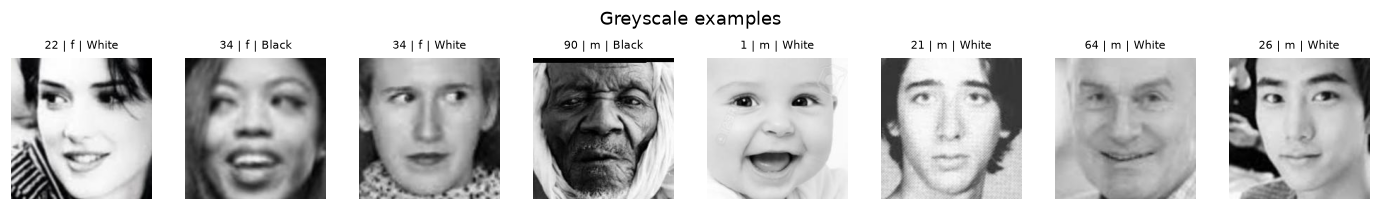

In [16]:
# Greyscale photos stored as RGB: the three channels are (almost) identical
def is_grey(f, tol=2):
    a = np.asarray(Image.open(IMG_DIR / f).convert("RGB"), dtype=np.int16)
    return np.abs(a[..., 0] - a[..., 1]).mean() < tol and np.abs(a[..., 1] - a[..., 2]).mean() < tol

sample = rng.choice(df.file, 2000, replace=False)
grey = [f for f in sample if is_grey(f)]
print(f"greyscale-looking images in a random sample of 2000: {len(grey)} ({100 * len(grey) / 2000:.1f} %)")
if grey:
    show(grey[:8], title="Greyscale examples")

## 7. Observations (to carry into the design and the report)

**Counts and files**
- 23,708 files. **5 malformed filenames**: 3 are missing the race field and 2 have typos (a space, a missing dot). We drop all 5, leaving **23,703 labelled images**.
- All images are **200×200 RGB**, already aligned and cropped. About 2.8 % are greyscale photos stored as RGB. A few have black borders from the alignment rotation.

**Duplicates and label noise (important)**
- **375 groups of byte-identical images** (765 images in total).
- **259 of these groups have conflicting labels**: age differs in 205 (median gap 5 years, max 48), gender in 40, race in 70. So the labels are noisy, and no model can be right for both copies.
- Plan: (a) keep one copy of each consistent group, (b) drop the conflicting groups, because we can't know which label is true. That leaves **≈ 23,054 images**. Duplicates must never end up on both sides of the train/test split. MD5 only finds *exact* copies; near-duplicates (re-encoded or resized) may still exist.

**Target (age)**
- Mean 33.3, median 29, std 19.9, range 1–116, right-skewed (skewness 0.62). 31 % of the images are aged 20–29, and fewer than 6 % are 70+.
- **Strong age heaping**: ages 40–90 that are multiples of 10 occur **2.4–5.9× more often** than their neighbours. Many labels for older people are rounded estimates, which puts a floor under the reachable MAE for the elderly.
- Constant predictors (preview on all labels): mean, MAE **15.35**; median, MAE 14.97. So "acceptable" needs MAE_own ≲ **9.2 years**. That's easy; the 1.15 × best-standard-model rule is the binding one.

**Groups and bias**
- Gender is balanced (52 % male / 48 % female). Race is imbalanced: White 42.5 %, Black 19.1 %, Indian 16.8 %, Asian 14.5 %, Others 7.1 %.
- **Age and group are confounded.** The 0–2 band is 39 % Asian and only 3 % Black. The 80+ band is 72 % White, and "Others" is almost absent above 60. Women dominate ages 3–29; men dominate 40–69 (up to 72 %).
- So the constant predictor already has very different per-group errors (Black 10.6 vs. White 17.9 years) **without looking at any face**. A raw per-group MAE therefore mixes model bias with differences in each group's age distribution. For a fair bias analysis we'll report per-group MAE **and** per-group MAE within age bands (or the improvement over the constant baseline per group).

**Consequences for the next steps**
1. Split: seeded train/val/test (e.g. 70/15/15), **stratified by age band × race**, with duplicates handled before splitting.
2. Loss: L1 or Huber rather than MSE, because of the skewed target and noisy, heaped labels. To be confirmed by an ablation.
3. Resolution: the originals are 200×200. We'll cache downsized copies once (e.g. 64 and 96 px) to save energy on every epoch. Input resolution is a natural ablation (error vs. energy).
4. Augmentation: horizontal flip, small random crop/scale and small rotation. Faces are already aligned, so keep it mild.